# Injection channels: LaBraM vs ridge

Per channel signal change and signed error change of the LaBraM and the ridge masked reconstruction, for one negative,
one positive and one mixed injection gain (`labram_inj_test.py`, `ridge_inj_test.py`): all trials uninjected vs injected,
and for one split seed half A uninjected vs half B injected and the null (half B uninjected).
The channels are those where the injected topography is strongest (|g|, as the ROI of the injection scripts). Per channel:
median over subjects, in %. The ROI row is the value of `summary*.csv`: median over subjects of every subject's mean over
the `settings.INJECTION_N_ROI` strongest channels.

The signed error change is the change of the reconstruction error (output - target), not the reconstructed change:
0 if the reconstruction follows the injected change, about -(the target's dB level change) if it ignores it.

In [37]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir('..')

from core import settings, plotting
from core import utils as core_utils

In [38]:
model_name = "masking_10_19_2"
head_model = "fsaverage"
band = f"all bands ({settings.FREQ_WINDOW_LABEL})"
negative_gain, positive_gain, mixed_gain = -0.25, 0.25, 1.0
split_seeds = [0, 1, 2]  # the a/b splits averaged in the split tables and figures (--split_seed values of the injection runs)
n_channels = settings.INJECTION_N_ROI  # channels shown per table, strongest first
output_roots = {"LaBraM": settings.BASE_DIR / "outputs" / "labram_injection",
                "ridge": settings.BASE_DIR / "outputs" / "ridge_inj_labram"}
save_to = "ridge"  # the tables are saved as csv next to this model's summary.csv (key of output_roots), None to not save

In [39]:
def channel_strength(mixed):
    """|g| per channel of the injected pattern (mixed: the sources weighted by their gains), strongest first."""
    topographies, relative_gains, _ = core_utils.injected_sources(
        head_model, settings.INJECTION_LABELS, settings.MIXED_INJECTION_GAINS if mixed else None,
        settings.INJECTION_SOURCE_DEPTH, settings.RSFREQ, settings.EGI_TO_1020_MAP, settings.CHORDER_STANDARD)
    G = np.stack(list(topographies.values()), axis=1)
    relative = np.array([relative_gains[name] for name in topographies])
    ch_names = [name.split(' ')[-1].split('-')[0] for name in settings.CHORDER_STANDARD]
    return pd.Series(np.abs(G @ relative), index=ch_names).sort_values(ascending=False)


def read_injection(model, injection, version):
    """
    injection{version}.csv of a model's run. A version with "{seed}" (e.g. "_split{seed}", "_split{seed}_null") is averaged
    over split_seeds per gain, band, subject and channel: the changes are log ratios, their mean over the splits.
    """
    folder = output_roots[model] / model_name / f"{injection}_{head_model}"
    if "{seed}" not in version:
        return pd.read_csv(folder / f"injection{version}.csv")
    splits = pd.concat([pd.read_csv(folder / f"injection{version.format(seed=seed)}.csv") for seed in split_seeds])
    return splits.groupby(["gain", "band", "subject", "channel"], as_index=False, sort=False).mean(numeric_only=True)


def channel_table(injection, gain, strength, version):
    """
    Signal and signed error change in % per channel (median over subjects) of both models, and the ROI row, from the
    injection{version}.csv of the runs (version "" all trials, "_split{seed}" a/b split, "_split{seed}_null" its null, both
    averaged over split_seeds, see read_injection).
    """
    roi = list(strength.index[:settings.INJECTION_N_ROI])
    columns = {}
    for model, root in output_roots.items():
        per_channel = read_injection(model, injection, version)
        per_channel = per_channel[(per_channel["band"] == band) & np.isclose(per_channel["gain"], gain)]
        kinds = {"signal (%)": "signal_change", f"{model} signed error (%)": "signed_error_change"} if model == "LaBraM"             else {f"{model} signed error (%)": "signed_error_change"}
        for name, kind in kinds.items():
            channels = per_channel.groupby("channel")[kind].median()
            roi_value = per_channel[per_channel["channel"].isin(roi)].groupby("subject")[kind].mean().median()
            columns[name] = pd.concat([channels, pd.Series({"ROI": roi_value})])
    table = 100 * (np.exp(pd.DataFrame(columns)) - 1)  # log ratio -> %
    table = table.loc[list(strength.index[:n_channels]) + ["ROI"]]
    table.insert(0, "|g|", strength.reindex(table.index))
    table.index.name = "channel"
    return table


def show(injection, gain, strength, version=""):
    """Displays the channel table and saves it next to the summary of save_to (null tables: one gain, they don't depend on it)."""
    table = channel_table(injection, gain, strength, version)
    version_file = version.replace("{seed}", "".join(map(str, split_seeds)))  # e.g. "_split012"
    if version.endswith("_null"):
        title, file_name = f"{injection} null, split seeds {split_seeds} averaged", f"channels{version_file}.csv"
    else:
        gain_name = f"mixed ×{gain:g}" if injection == "mixed" else f"{100 * gain:+g} %"
        gain_file = f"mixed{gain:g}" if injection == "mixed" else f"gain{gain:g}"
        title = f"{gain_name}" + (f", split seeds {split_seeds} averaged (half B injected vs half A)" if version else ", all trials")
        file_name = f"channels_{gain_file}{version_file}.csv"
    print(title)
    display(table.round({column: 2 if column == "|g|" else 1 for column in table.columns}))
    if save_to is not None:
        path = output_roots[save_to] / model_name / f"{injection}_{head_model}" / file_name
        table.to_csv(path)
        print(f"saved to {path}")

In [40]:
single_strength = channel_strength(mixed=False)
mixed_strength = channel_strength(mixed=True)
print(f"ROI single: {', '.join(single_strength.index[:settings.INJECTION_N_ROI])}")
print(f"ROI mixed: {', '.join(mixed_strength.index[:settings.INJECTION_N_ROI])}")
print("Mixed injection: " + ", ".join(f"{name} {100 * mixed_gain * g:+g} %" for name, g in settings.MIXED_INJECTION_GAINS.items()))

ROI single: P3, PZ, P4, T2
ROI mixed: T5, P3, T6, P4
Mixed injection: pericalcarine +25 %, lateraloccipital -25 %


## All trials: uninjected vs injected

In [41]:
show("single", negative_gain, single_strength)

-25 %, all trials


,|g|,signal (%),LaBraM signed error (%),ridge signed error (%)
channel,,,,
P3,1.00,-25.7,21.9,14.8
PZ,0.85,-23.9,20.3,21.9
P4,0.71,-13.8,7.3,9.9
T2,0.60,-13.7,4.6,-9.1
ROI,NaN,-19.5,13.5,8.4


saved to outputs\ridge_inj_labram\masking_10_19_2\single_fsaverage\channels_gain-0.25.csv


In [42]:
show("single", positive_gain, single_strength)

+25 %, all trials


,|g|,signal (%),LaBraM signed error (%),ridge signed error (%)
channel,,,,
P3,1.00,40.4,-20.4,-15.1
PZ,0.85,31.0,-17.0,-18.2
P4,0.71,19.9,-9.7,-11.9
T2,0.60,16.2,-5.0,9.7
ROI,NaN,25.9,-13.5,-8.8


saved to outputs\ridge_inj_labram\masking_10_19_2\single_fsaverage\channels_gain0.25.csv


In [43]:
show("mixed", mixed_gain, mixed_strength)

mixed ×1, all trials


,|g|,signal (%),LaBraM signed error (%),ridge signed error (%)
channel,,,,
T5,0.36,-14.4,12.1,-7.5
P3,0.29,32.2,-19.7,-13.8
T6,0.26,-19.7,14.3,-7.1
P4,0.23,13.0,-9.4,-25.5
ROI,NaN,1.6,-1.7,-14.2


saved to outputs\ridge_inj_labram\masking_10_19_2\mixed_fsaverage\channels_mixed1.csv


## A/B split: half A uninjected vs half B injected, and the null (half B uninjected)

In [44]:
show("single", negative_gain, single_strength, "_split{seed}")

-25 %, split seeds [0, 1, 2] averaged (half B injected vs half A)


,|g|,signal (%),LaBraM signed error (%),ridge signed error (%)
channel,,,,
P3,1.00,-24.6,21.6,12.3
PZ,0.85,-22.4,20.4,20.0
P4,0.71,-13.8,6.0,9.2
T2,0.60,-12.2,4.4,-9.3
ROI,NaN,-18.5,12.7,10.1


saved to outputs\ridge_inj_labram\masking_10_19_2\single_fsaverage\channels_gain-0.25_split012.csv


In [45]:
show("single", positive_gain, single_strength, "_split{seed}")

+25 %, split seeds [0, 1, 2] averaged (half B injected vs half A)


,|g|,signal (%),LaBraM signed error (%),ridge signed error (%)
channel,,,,
P3,1.00,40.3,-20.6,-13.2
PZ,0.85,33.1,-17.9,-17.5
P4,0.71,19.4,-10.1,-11.4
T2,0.60,17.5,-5.7,10.9
ROI,NaN,26.5,-13.5,-8.1


saved to outputs\ridge_inj_labram\masking_10_19_2\single_fsaverage\channels_gain0.25_split012.csv


In [46]:
show("mixed", mixed_gain, mixed_strength, "_split{seed}")

mixed ×1, split seeds [0, 1, 2] averaged (half B injected vs half A)


,|g|,signal (%),LaBraM signed error (%),ridge signed error (%)
channel,,,,
T5,0.36,-13.4,13.2,-7.3
P3,0.29,32.7,-20.1,-12.6
T6,0.26,-19.4,14.6,-8.6
P4,0.23,13.5,-9.7,-25.1
ROI,NaN,2.5,-1.5,-14.3


saved to outputs\ridge_inj_labram\masking_10_19_2\mixed_fsaverage\channels_mixed1_split012.csv


In [47]:
show("single", negative_gain, single_strength, "_split{seed}_null")

single null, split seeds [0, 1, 2] averaged


,|g|,signal (%),LaBraM signed error (%),ridge signed error (%)
channel,,,,
P3,1.00,2.0,-0.3,1.7
PZ,0.85,1.9,-0.4,0.7
P4,0.71,0.9,-0.5,0.2
T2,0.60,1.3,-0.9,0.6
ROI,NaN,1.3,-0.5,0.8


saved to outputs\ridge_inj_labram\masking_10_19_2\single_fsaverage\channels_split012_null.csv


In [48]:
show("mixed", mixed_gain, mixed_strength, "_split{seed}_null")

mixed null, split seeds [0, 1, 2] averaged


,|g|,signal (%),LaBraM signed error (%),ridge signed error (%)
channel,,,,
T5,0.36,0.8,0.7,0.2
P3,0.29,2.0,-0.4,1.7
T6,0.26,0.8,-0.1,-1.4
P4,0.23,0.9,-0.5,0.2
ROI,NaN,0.7,-0.2,1.4


saved to outputs\ridge_inj_labram\masking_10_19_2\mixed_fsaverage\channels_split012_null.csv


## Ridge alpha sweep

Validation R² (time-domain amplitude, mean over target channels) per relative alpha of the ridge injection run, per fold; the star is the alpha the run selected (`ridge_inj_test.fit_ridge_models`).

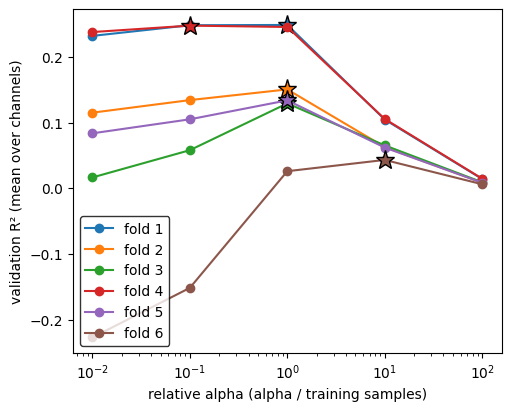

In [49]:
sweep = pd.read_csv(output_roots["ridge"] / model_name / "alpha_sweep.csv")
mean_r2 = sweep.groupby(["fold", "alpha"], as_index=False)["val_r2"].mean()

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
for fold, rows in mean_r2.groupby("fold"):
    line, = ax.plot(rows["alpha"], rows["val_r2"], marker="o", label=f"fold {fold}")
    best = rows.loc[rows["val_r2"].idxmax()]
    ax.plot(best["alpha"], best["val_r2"], marker="*", markersize=14, color=line.get_color(), markeredgecolor="black")
ax.set_xscale("log")
ax.set_xlabel("relative alpha (alpha / training samples)")
ax.set_ylabel("validation R² (mean over channels)")
ax.legend(loc="lower left").get_frame().set_edgecolor("black")
plt.show()
plotting.save_button(fig, save_dir=settings.THESIS_FIGURE_DIR, default_name="ridge_alpha_sweep")

## Signed error vs signal change

Per channel and gain: mean over subjects of the signal change (x) and of the signed error change (y), error bars ± 1.96 SE
of the signed error change (of the log ratios, then in %). With split seeds every subject x seed value is pooled:
mean over all values, SE = pooled SD (every value centred on its seed's mean) / sqrt(number of subjects), the SE of a
single split (averaging every subject over the seeds first would shrink it). On the dashed curve the reconstruction ignores the change (signed error
= -level change, drawn for a level change equal to the signal change), on 0 it follows it. Same trials: all trials
uninjected vs injected. Split: half A uninjected vs half B injected, the `split_seeds` pooled per subject and channel,
nothing subtracted, so the difference of the halves (trial-to-trial noise) is in it. Null: half A vs half B, both uninjected,
pooled over `split_seeds` the same way,
one point per channel (it doesn't depend on the gain), on its own below; in the split and same-trials figures the grey band:
the null's mean ± 1.96 SE (the 95 % range of a channel's null mean in one split; mean and SE per channel as above,
averaged over the panel's channels; log ratios, shown in %), as in the decoding injection figures.

In [50]:
def load_changes(model, injection, version):
    """
    Signal and signed error change (log ratios) per gain, subject, channel and split seed of the band, from
    injection{version}.csv: a "{seed}" version one file per seed of split_seeds, not averaged (seed 0 otherwise).
    """
    folder = output_roots[model] / model_name / f"{injection}_{head_model}"
    seeds = split_seeds if "{seed}" in version else [0]
    per_channel = pd.concat([pd.read_csv(folder / f"injection{version.format(seed=seed)}.csv").assign(seed=seed) for seed in seeds])
    per_channel = per_channel[(per_channel["band"] == band) & (per_channel["gain"] != 0)]
    return per_channel.set_index(["gain", "subject", "channel", "seed"])[["signal_change", "signed_error_change"]]


def single_split_se(values):
    """
    SE of one split from a Series of subject x seed values (index levels "subject" and "seed"): pooled SD (every value
    centred on its seed's mean) / sqrt(number of subjects). With one seed it is the SE over subjects.
    """
    values = values.dropna()
    centred = values - values.groupby(level="seed").transform("mean")
    n_seeds, n_subjects = values.index.get_level_values("seed").nunique(), values.index.get_level_values("subject").nunique()
    return np.sqrt((centred ** 2).sum() / (len(values) - n_seeds)) / np.sqrt(n_subjects)


def recovery(model, injection, version=""):
    """
    Per gain and channel, in %: mean over the subject (x split seed) values of the signal and the signed error change and
    the signed error change ± 1.96 single-split SE (low, high, single_split_se), of the log ratios of injection{version}.csv
    ("" all trials, "_split{seed}" half A uninjected vs half B injected, "_split{seed}_null" its null, the same for every gain).
    """
    changes = load_changes(model, injection, version)
    grouped = changes.groupby(["gain", "channel"])
    signed, se = grouped["signed_error_change"].mean(), grouped["signed_error_change"].apply(single_split_se)
    stats = pd.DataFrame({"signal": grouped["signal_change"].mean(), "signed": signed, "low": signed - 1.96 * se, "high": signed + 1.96 * se})
    return (100 * (np.exp(stats) - 1)).reset_index()


def plot_recovery(version, default_name, letters="ABCD", svg_path=None, null_version=None):
    """
    Signed error vs signal change of the n_channels strongest channels: LaBraM and ridge (columns), single and mixed (rows),
    of injection{version}.csv ("" all trials, "_split{seed}" the split with its null as a grey band, "_split{seed}_null"
    the null alone). letters: the panel labels, svg_path: the figure is saved there as well (None: only the save button).
    null_version: the null drawn as the grey band, e.g. "_split{seed}_null" (None: the split's own null, none otherwise).
    """
    if null_version is None and version.startswith("_split") and not version.endswith("_null"):
        null_version = f"{version}_null"
    channels = {"single": list(single_strength.index[:n_channels]), "mixed": list(mixed_strength.index[:n_channels])}
    colors = {channel: f"C{i}" for i, channel in enumerate(dict.fromkeys(channels["single"] + channels["mixed"]))}
    fig, axd = plt.subplot_mosaic([["A", "B"], ["C", "D"]], figsize=(10, 9), layout="constrained")
    panels = {"A": ("LaBraM", "single"), "B": ("ridge", "single"), "C": ("LaBraM", "mixed"), "D": ("ridge", "mixed")}
    for key, (model, injection) in panels.items():
        ax = axd[key]
        points = recovery(model, injection, version)
        if version.endswith("_null"):
            points = points[points["gain"] == points["gain"].iloc[0]]  # the null doesn't depend on the gain
        for channel in channels[injection]:
            rows = points[points["channel"] == channel].sort_values("gain")
            ax.errorbar(rows["signal"], rows["signed"], yerr=[rows["signed"] - rows["low"], rows["high"] - rows["signed"]],
                        marker="o", capsize=3, color=colors[channel], label=channel)
        if null_version is not None:
            # the null's signed error change of the panel's channels (one gain: the null doesn't depend on it): mean and
            # single-split SE per channel, as the points, averaged over the channels; mean ± 1.96 SE (log ratios, then in %)
            null = load_changes(model, injection, null_version)
            null = null[(null.index.get_level_values("gain") == null.index.get_level_values("gain")[0])
                        & null.index.get_level_values("channel").isin(channels[injection])]
            by_channel = null.groupby(level="channel")["signed_error_change"]
            low, high = 100 * (np.exp(by_channel.mean().mean() + np.array([-1.96, 1.96]) * by_channel.apply(single_split_se).mean()) - 1)
            ax.axhspan(low, high, color="gray", alpha=0.2, linewidth=0, label="null ± 1.96 SE")
            # least-squares slope of the output's level change on the target's level change in the null, over the same subject x
            # channel values: 1 = the output follows the target's level change, 0 = it ignores it
            null_levels = read_injection(model, injection, null_version)
            null_levels = null_levels[(null_levels["band"] == band) & (null_levels["gain"] == null_levels["gain"].iloc[0])
                                      & null_levels["channel"].isin(channels[injection])]
            slope = np.polyfit(null_levels["level_change"], null_levels["level_change"] + null_levels["signed_error_change"], 1)[0]
            print(f"{model}, {injection}: null band {low:+.2f} % to {high:+.2f} %, slope of the output on the target level change = {slope:.2f}")
        x = np.linspace(min(points["signal"].min(), 0) - 5, max(points["signal"].max(), 0) + 5, 200)
        ax.axhline(0, color="gray", linewidth=0.8)
        ax.axvline(0, color="gray", linewidth=0.8)
        ax.set_xlabel("signal change (%)")
        ax.set_ylabel("signed error change (%)")
        ax.set_title(f"{model}, {'single source' if injection == 'single' else 'mixed injection'}")
        ax.legend(loc="upper right").get_frame().set_edgecolor("black")
    for left, right in (("A", "B"), ("C", "D")):
        # one x and y range per row, covering the data of both panels (sharing alone keeps the left panel's limits and
        # cuts off the right panel's points outside them)
        x_limits, y_limits = [*axd[left].get_xlim(), *axd[right].get_xlim()], [*axd[left].get_ylim(), *axd[right].get_ylim()]
        axd[right].sharex(axd[left])
        axd[right].sharey(axd[left])
        axd[left].set_xlim(min(x_limits), max(x_limits))
        axd[left].set_ylim(min(y_limits), max(y_limits))
    for key, letter in zip("ABCD", letters):
        axd[key].text(-0.12, 1.05, letter, transform=axd[key].transAxes, fontsize=14, fontweight="bold", va="bottom", gid="panel_label")
    if svg_path is not None:
        svg_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(svg_path, bbox_inches="tight")
    plt.show()
    plotting.save_panels(fig, axd, settings.THESIS_FIGURE_DIR, settings.SUBFIGURES_DIR, default_name=default_name)

LaBraM, single: null band -1.91 % to +0.81 %, slope of the output on the target level change = 0.49
ridge, single: null band -4.86 % to +5.95 %, slope of the output on the target level change = 0.66
LaBraM, mixed: null band -1.50 % to +1.38 %, slope of the output on the target level change = 0.49
ridge, mixed: null band -5.03 % to +6.10 %, slope of the output on the target level change = 0.77


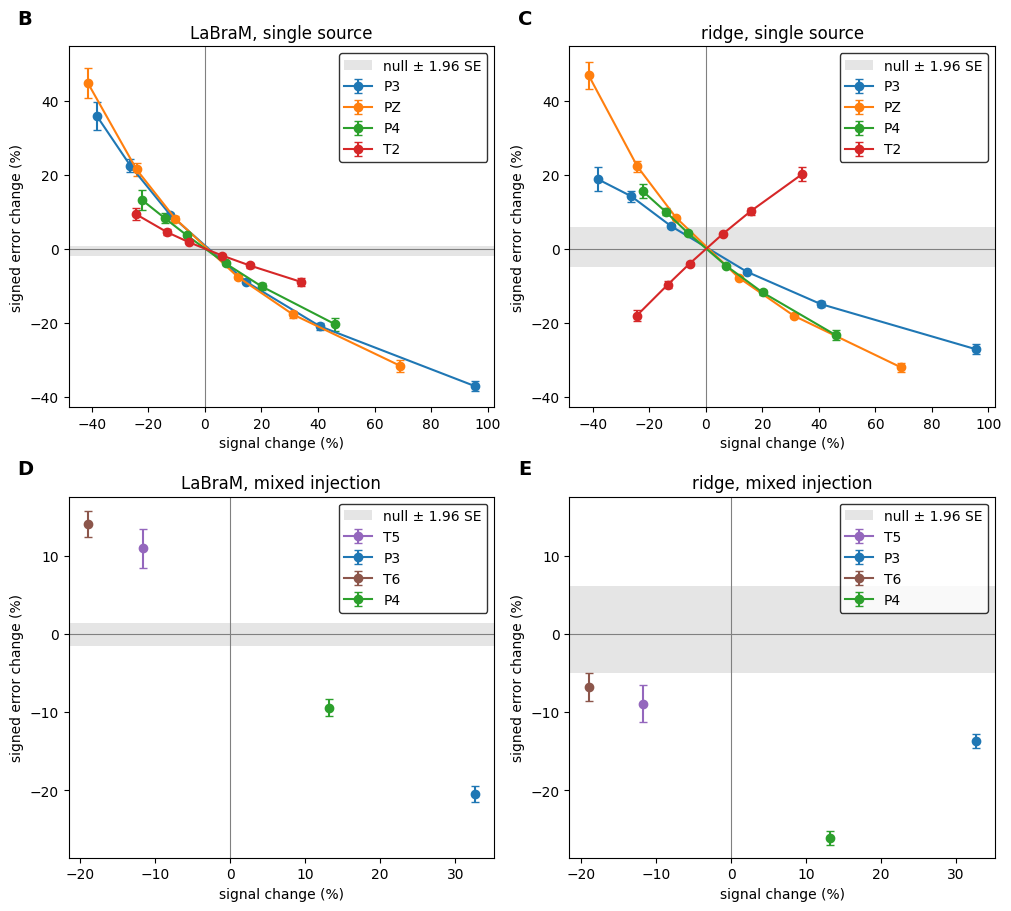

In [51]:
# B-E of the thesis figure below (panel A: the topomaps), also saved as an SVG for it. Grey band: the null of the splits
# (two halves of the trials, both uninjected, split_seeds pooled), the trial-to-trial noise a session comparison would add
same_trials_svg = settings.SUBFIGURES_DIR / "injection_signed_error_same_trials_BCDE.svg"
plot_recovery("", "injection_signed_error_same_trials", letters="BCDE", svg_path=same_trials_svg,
              null_version="_split{seed}_null")

saved to outputs\plots\thesis_figures\injection_signed_error_same_trials_topomaps.svg, topomaps to outputs\plots\thesis_figures\subfigures


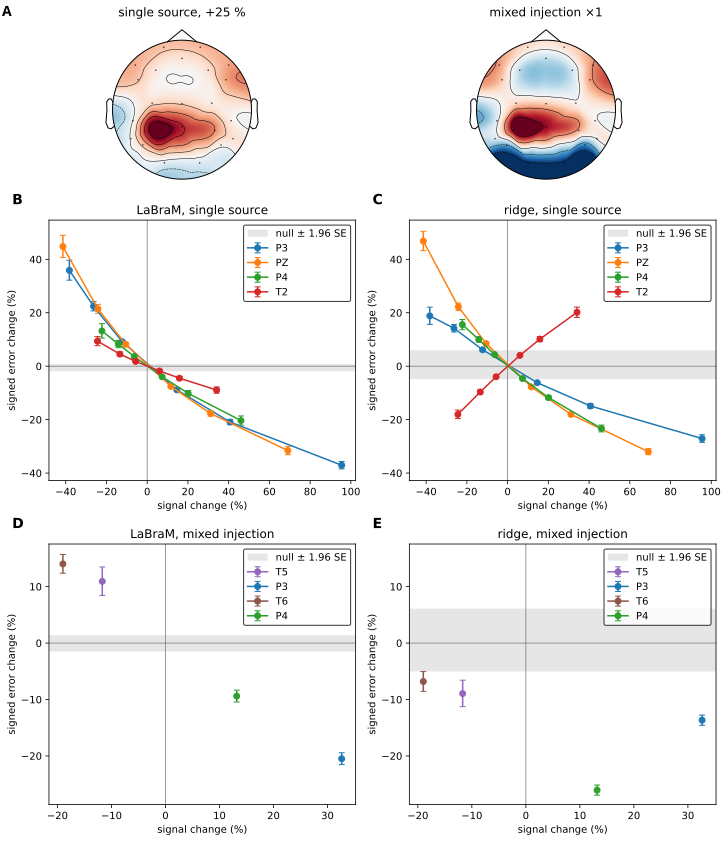

In [52]:
# THESIS FIGURE: the same-trials figure (B-E, cell above) with a first row (A): the target power change of the injection,
# the single source at topomap_gain and the mixed injection, in the band, median over subjects per channel (LaBraM's
# targets, the ridge's are the same). Each map has its own symmetric colour scale and no colour bar: only the topography
# matters. Both maps are saved as separate SVGs and stacked above the same-trials SVG with svgutils.
import mne
import svgutils.compose as sc
from IPython.display import SVG
from core.plot_data_processing import create_topomap_info

topomap_gain = 0.25
topomap_dir = settings.SUBFIGURES_DIR
composed_svg = settings.THESIS_FIGURE_DIR / "injection_signed_error_same_trials_topomaps.svg"

topomap_dir.mkdir(parents=True, exist_ok=True)
info = create_topomap_info()  # 10-20 labels at the positions of the recording electrodes, in CHORDER_STANDARD order
ch_names = [name.split(' ')[-1].split('-')[0] for name in settings.CHORDER_STANDARD]
topomap_svgs = {}
for injection, gain, title in (("single", topomap_gain, f"single source, {100 * topomap_gain:+g} %"),
                               ("mixed", mixed_gain, f"mixed injection ×{mixed_gain:g}")):
    per_channel = pd.read_csv(output_roots["LaBraM"] / model_name / f"{injection}_{head_model}" / "injection.csv")
    per_channel = per_channel[(per_channel["band"] == band) & np.isclose(per_channel["gain"], gain)]
    values = (100 * (np.exp(per_channel.groupby("channel")["signal_change"].median()) - 1)).reindex(ch_names).to_numpy(dtype=float)
    limit = np.nanmax(np.abs(values))
    fig, ax = plt.subplots(figsize=(3, 3))
    mne.viz.plot_topomap(values, info, axes=ax, show=False, vlim=(-limit, limit), cmap="RdBu_r")
    ax.set_title(title)
    topomap_svgs[injection] = topomap_dir / f"injection_power_change_{injection}.svg"
    fig.savefig(topomap_svgs[injection], bbox_inches="tight")
    plt.close(fig)

# A: the two maps side by side, each centred in its half of the same-trials figure's width, above it. fix_mpl: the
# matplotlib SVGs in pt are read as px, so their contents and sizes stay in one unit
figure = sc.SVG(same_trials_svg, fix_mpl=True)
maps = [sc.SVG(topomap_svgs[injection], fix_mpl=True) for injection in ("single", "mixed")]
scale = min(1.0, figure.width / 2 / max(m.width for m in maps))
top = max(m.height for m in maps) * scale
panels = [m.move(i * figure.width / 2 + (figure.width / 2 - m.width * scale) / 2, 0).scale(scale) for i, m in enumerate(maps)]
composed_svg.parent.mkdir(parents=True, exist_ok=True)
sc.Figure(f"{figure.width}px", f"{top + figure.height}px", *panels, figure.move(0, top),
          sc.Text("A", 2, 16, size=14, weight="bold", font="sans-serif")).save(composed_svg)
print(f"saved to {composed_svg}, topomaps to {topomap_dir}")
display(SVG(filename=str(composed_svg)))

split seeds [0, 1, 2] pooled: half A uninjected vs half B injected
LaBraM, single: null band -1.91 % to +0.81 %, slope of the output on the target level change = 0.49
ridge, single: null band -4.86 % to +5.95 %, slope of the output on the target level change = 0.66
LaBraM, mixed: null band -1.50 % to +1.38 %, slope of the output on the target level change = 0.49
ridge, mixed: null band -5.03 % to +6.10 %, slope of the output on the target level change = 0.77


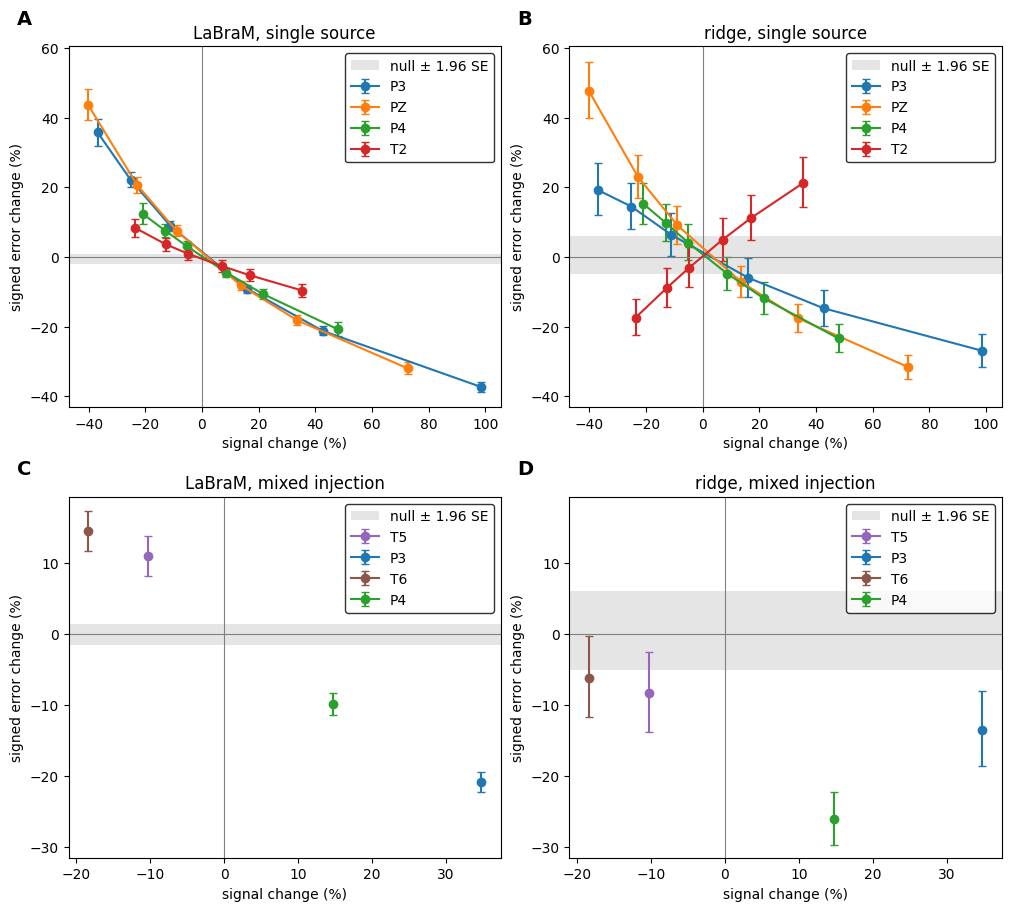

In [53]:
print(f"split seeds {split_seeds} pooled: half A uninjected vs half B injected")
plot_recovery("_split{seed}", "injection_signed_error_split")

split seeds [0, 1, 2] pooled, null: half A vs half B, both uninjected


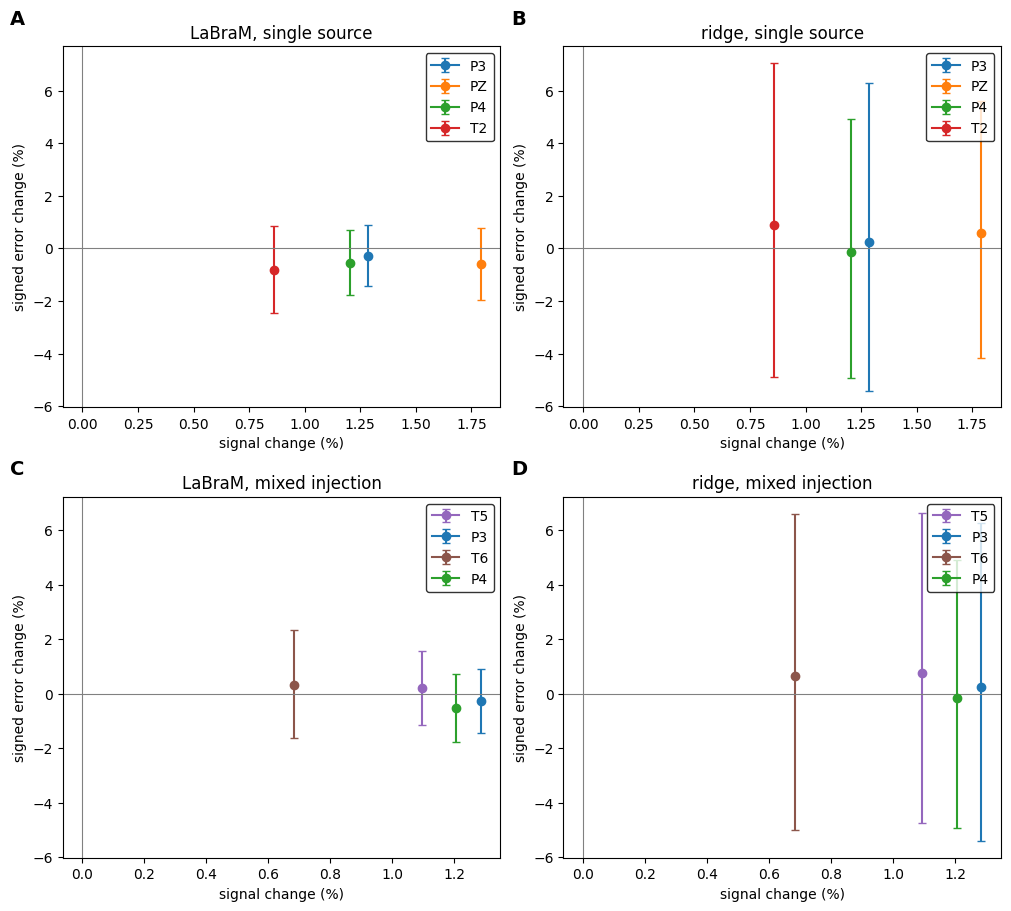

In [54]:
print(f"split seeds {split_seeds} pooled, null: half A vs half B, both uninjected")
plot_recovery("_split{seed}_null", "injection_signed_error_split_null")